# Notebook 1. Embeddings



Objetivo: entender qué es un embedding, cómo se mide la similitud entre textos y qué cambia entre modelos.
Usamos tres modelos multilingües: BGE-M3 (por defecto), Qwen3-Embedding-0.6B y multilingual-e5-large.

Referencias:
- Ficha de BGE-M3: https://huggingface.co/BAAI/bge-m3 (artículo: https://arxiv.org/abs/2402.03216)
- Ficha de Qwen3-Embedding-0.6B: https://huggingface.co/Qwen/Qwen3-Embedding-0.6B
- Ficha de multilingual-e5-large: https://huggingface.co/intfloat/multilingual-e5-large

In [2]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/ander_arias/projects/reto_1_1-2627-Rag-Modal-Multimodal-OCR/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada
Trazas:      jsonl /home/ander_arias/projects/reto_1_1-2627-Rag-Modal-Multimodal-OCR/trazas/trazas.jsonl  (alumno: ander_arias)


## 1. Qué es un embedding

Un modelo de embeddings convierte un texto en un vector de longitud fija. Textos con significado parecido
quedan cerca en ese espacio. BGE-M3 produce vectores de 1024 dimensiones. `rag_lab.models.embed`
carga el modelo en fp16 si hay GPU, aplica el prefijo que pide su ficha y guarda los vectores en disco.

In [3]:
import numpy as np
from rag_lab import models

sentences = [
    "El tren a Bilbao sale a las ocho de la mañana.",
    "Mañana a las 8 sale el tren hacia Bilbao.",
    "Los domingos cocino paella para toda la familia.",
]
vectors = models.embed(sentences, role="doc", model="BAAI/bge-m3")
print("Forma:", vectors.shape)
print("Primeras 8 componentes de la frase 1:", vectors[0][:8].round(4))
print(models.gpu_memory())

Forma: (3, 1024)
Primeras 8 componentes de la frase 1: [-0.001   0.0111 -0.0537  0.0002 -0.0299 -0.0079  0.0265  0.0288]
GPU: 0.00 GB en uso, pico 0.00 GB


## 2. Similitud coseno

La similitud coseno es el producto escalar dividido por el producto de las normas: 1 si los vectores apuntan
igual, 0 si son ortogonales. Como `embed` devuelve vectores normalizados, basta con el producto escalar.

In [3]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        print(f"{cosine(vectors[i], vectors[j]):.3f}  |  {sentences[i]}  <->  {sentences[j]}")
print("Producto escalar de 1 y 2:", round(float(vectors[0] @ vectors[1]), 3))

0.955  |  El tren a Bilbao sale a las ocho de la mañana.  <->  Mañana a las 8 sale el tren hacia Bilbao.
0.419  |  El tren a Bilbao sale a las ocho de la mañana.  <->  Los domingos cocino paella para toda la familia.
0.460  |  Mañana a las 8 sale el tren hacia Bilbao.  <->  Los domingos cocino paella para toda la familia.
Producto escalar de 1 y 2: 0.955


## 3. Visualización en 2D

Proyectamos con PCA frases de cuatro temas. Si el modelo captura el significado, cada tema forma un grupo.
La proyección a 2D pierde información: sirve para intuir, no para medir.

/home/ander_arias/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


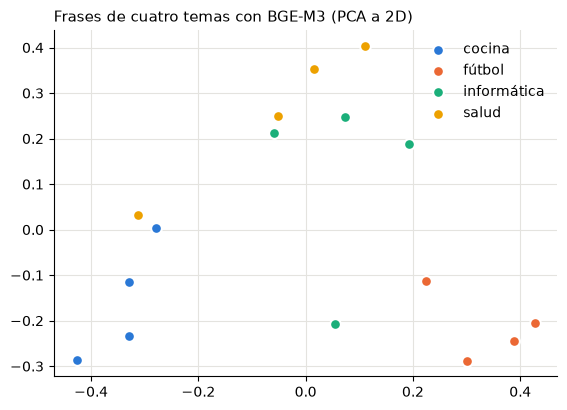

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

topics = {
    "cocina": ["La paella lleva arroz, azafrán y caldo.", "Hornea el bizcocho cuarenta minutos.",
               "Corta la cebolla en juliana fina.", "El marmitako es un guiso de bonito."],
    "fútbol": ["El delantero marcó de penalti en el último minuto.", "El árbitro expulsó al defensa.",
               "El equipo ganó la liga tras empatar el domingo.", "El portero detuvo el lanzamiento."],
    "informática": ["El servidor se reinició tras la actualización.", "Despliega el contenedor con Docker.",
                    "La consulta SQL tarda demasiado.", "El pipeline de CI ejecuta los tests."],
    "salud": ["El paciente tiene fiebre y tos seca.", "Toma el antibiótico cada ocho horas.",
              "La enfermera midió la tensión arterial.", "El médico pidió una analítica completa."],
}
texts = [t for group in topics.values() for t in group]
labels = [topic for topic, group in topics.items() for _ in group]
coords = PCA(n_components=2, random_state=CFG.SEED).fit_transform(models.embed(texts, "doc", "BAAI/bge-m3"))

palette = dict(zip(topics, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for topic in topics:
    idx = [i for i, e in enumerate(labels) if e == topic]
    ax.scatter(coords[idx, 0], coords[idx, 1], s=60, color=palette[topic], label=topic, edgecolor="white", linewidth=1.5)
ax.set_title("Frases de cuatro temas con BGE-M3 (PCA a 2D)", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 4. Búsqueda semántica mínima

Buscar es codificar la consulta, calcular su similitud con cada documento y ordenar. Ojo al rol:
la consulta se codifica como `query` y los documentos como `doc`, porque algunos modelos usan prefijos distintos.

In [5]:
corpus = [
    "La matrícula del ciclo formativo se abre en septiembre.",
    "El proyecto se financia con fondos europeos NextGenerationEU.",
    "Los alumnos harán prácticas en empresas del sector.",
    "El sistema despliega modelos de IA en la nube con integración continua.",
    "La cafetería del centro abre a las ocho.",
    "Se medirá la satisfacción del alumnado con encuestas.",
    "El presupuesto total del proyecto supera los cien mil euros.",
    "Las clases de programación se imparten por la tarde.",
]

def search(query, corpus, model="BAAI/bge-m3", k=3):
    q = models.embed([query], "query", model)[0]
    d = models.embed(corpus, "doc", model)
    scores = d @ q
    return [(round(float(scores[i]), 3), corpus[i]) for i in np.argsort(-scores)[:k]]

for query in ["¿Quién paga el proyecto?", "¿Cómo se evaluará la opinión de los estudiantes?"]:
    print(query)
    for score, text in search(query, corpus):
        print("  ", score, text)

¿Quién paga el proyecto?
   0.617 El presupuesto total del proyecto supera los cien mil euros.
   0.613 El proyecto se financia con fondos europeos NextGenerationEU.
   0.442 Los alumnos harán prácticas en empresas del sector.
¿Cómo se evaluará la opinión de los estudiantes?
   0.725 Se medirá la satisfacción del alumnado con encuestas.
   0.558 Los alumnos harán prácticas en empresas del sector.
   0.461 La matrícula del ciclo formativo se abre en septiembre.


## 5. Tres modelos y sus prefijos

Cada modelo se entrenó con un formato de entrada concreto y hay que respetarlo:
- BGE-M3: sin instrucción ni prefijo.
- Qwen3-Embedding: instrucción solo en la consulta (`prompt_name="query"`), nada en los documentos.
- multilingual-e5: `query: ` en la consulta y `passage: ` en los documentos.

In [6]:
import pandas as pd

print(pd.DataFrame(models.PROFILES).T.fillna(""))
qwen = models.sentence_transformer("Qwen/Qwen3-Embedding-0.6B")
print("\nInstrucción de Qwen3 para consultas:", repr(qwen.prompts["query"]))
del qwen
models.release()

                                  query        doc query_prompt_name
BAAI/bge-m3                                                         
Qwen/Qwen3-Embedding-0.6B                                      query
intfloat/multilingual-e5-large  query:   passage:                   
intfloat/multilingual-e5-base   query:   passage:                   

Instrucción de Qwen3 para consultas: 'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'


In [7]:
MODELS = ["BAAI/bge-m3", "Qwen/Qwen3-Embedding-0.6B", "intfloat/multilingual-e5-large"]
queries = ["¿Quién paga el proyecto?", "¿Cuándo empieza la matrícula?", "¿Dónde se despliegan los modelos?"]

rows = []
for model in MODELS:
    for query in queries:
        score, text = search(query, corpus, model, k=1)[0]
        rows.append({"modelo": model.split("/")[1], "consulta": query, "top-1": text, "similitud": score})
    models.release()  # un modelo cada vez en la GPU
pd.DataFrame(rows).pivot(index="consulta", columns="modelo", values="similitud")

modelo,Qwen3-Embedding-0.6B,bge-m3,multilingual-e5-large
consulta,,,
¿Cuándo empieza la matrícula?,0.750,0.774,0.852
¿Dónde se despliegan los modelos?,0.451,0.533,0.821
¿Quién paga el proyecto?,0.572,0.617,0.831


Las similitudes no son comparables entre modelos: cada uno tiene su propia escala. Lo que importa es el orden.
Veamos qué pasa si nos saltamos el prefijo de e5.

In [8]:
e5 = models.sentence_transformer("intfloat/multilingual-e5-large")
query = "¿Quién paga el proyecto?"
with_prefix = models.embed(corpus, "doc", "intfloat/multilingual-e5-large") @ models.embed([query], "query", "intfloat/multilingual-e5-large")[0]
no_prefix = (e5.encode(corpus, normalize_embeddings=True) @ e5.encode([query], normalize_embeddings=True)[0]).astype("float32")
del e5
models.release()
pd.DataFrame({"documento": corpus, "con prefijos": with_prefix.round(3), "sin prefijos": no_prefix.round(3)}).sort_values("con prefijos", ascending=False)

,documento,con prefijos,sin prefijos
1,El proyecto se financia con fondos europeos Ne...,0.831,0.837
6,El presupuesto total del proyecto supera los c...,0.824,0.843
2,Los alumnos harán prácticas en empresas del se...,0.760,0.765
0,La matrícula del ciclo formativo se abre en se...,0.760,0.771
3,El sistema despliega modelos de IA en la nube ...,0.759,0.764
5,Se medirá la satisfacción del alumnado con enc...,0.753,0.759
7,Las clases de programación se imparten por la ...,0.737,0.764
4,La cafetería del centro abre a las ocho.,0.723,0.726


## 6. Entre idiomas

Comprobamos si cada modelo coloca cerca la misma idea escrita en idiomas distintos. Comparamos una consulta en
español con la misma frase en otros idiomas y con una frase en español que no tiene nada que ver.
Fíjate en el euskera y en la frase de otro tema: no todos los modelos se comportan igual.

In [9]:
query = "¿A qué hora sale el tren?"
docs = {
    "es": "El tren sale a las ocho.",
    "en": "The train leaves at eight o'clock.",
    "fr": "Le train part à huit heures.",
    "eu": "Trena zortzietan ateratzen da.",
    "es (otro tema)": "La biblioteca cierra en agosto.",
}
table = {}
for model in MODELS:
    q = models.embed([query], "query", model)[0]
    d = models.embed(list(docs.values()), "doc", model)
    table[model.split("/")[1]] = (d @ q).round(3)
    models.release()
pd.DataFrame(table, index=list(docs))

,bge-m3,Qwen3-Embedding-0.6B,multilingual-e5-large
es,0.848,0.744,0.864
en,0.814,0.629,0.806
fr,0.836,0.631,0.823
eu,0.832,0.232,0.855
es (otro tema),0.385,0.263,0.715


## 7. Frases parecidas con significado distinto

Un embedding resume el texto en un vector y pierde matices: orden de los papeles, negaciones, cifras.
Por eso dos frases con las mismas palabras y significado opuesto pueden tener una similitud muy alta.

In [10]:
pairs = [
    ("El perro mordió al cartero.", "El cartero mordió al perro."),
    ("El tratamiento es eficaz.", "El tratamiento no es eficaz."),
    ("El presupuesto es de 4.000 euros.", "El presupuesto es de 40.000 euros."),
    ("Me senté en el banco del parque.", "Abrí una cuenta en el banco."),
    ("El tren sale a las ocho.", "El tren a Bilbao sale a las 8."),
]
table = {}
for model in MODELS:
    a = models.embed([p[0] for p in pairs], "doc", model)
    b = models.embed([p[1] for p in pairs], "doc", model)
    table[model.split("/")[1]] = (a * b).sum(axis=1).round(3)
    models.release()
pd.DataFrame(table, index=[f"{x}  |  {y}" for x, y in pairs])

,bge-m3,Qwen3-Embedding-0.6B,multilingual-e5-large
El perro mordió al cartero. | El cartero mordió al perro.,0.983,0.930,0.993
El tratamiento es eficaz. | El tratamiento no es eficaz.,0.740,0.774,0.897
El presupuesto es de 4.000 euros. | El presupuesto es de 40.000 euros.,0.941,0.986,0.980
Me senté en el banco del parque. | Abrí una cuenta en el banco.,0.618,0.520,0.877
El tren sale a las ocho. | El tren a Bilbao sale a las 8.,0.844,0.771,0.957


In [11]:
# TODO: añade dos pares de frases propios (por ejemplo, con una fecha o un nombre cambiado)
# y calcula su similitud con los tres modelos. ¿Cuál distingue mejor el cambio?
my_pairs = [
    # ("frase A", "frase B"),
]

def pair_similarity(pairs, model):
    # Completa: codifica las dos columnas con models.embed(..., "doc", model) y devuelve
    # el producto escalar fila a fila
    return None

if my_pairs:
    for model in MODELS:
        print(model, pair_similarity(my_pairs, model))
        models.release()
else:
    print("Completa el TODO: añade tus pares a my_pairs.")

Completa el TODO: añade tus pares a my_pairs.


In [12]:
models.release()
print(models.gpu_memory())

GPU: 0.00 GB en uso, pico 0.00 GB


## Qué hemos visto

- Un embedding es un vector; la similitud coseno mide cercanía de significado y la búsqueda semántica es ordenar por ella.
- Cada modelo exige su formato de entrada (prefijos o instrucción) y tiene su propia escala de similitudes.
- Los modelos multilingües acercan idiomas distintos, pero confunden frases con las mismas palabras y distinto significado.

## Ejercicio propuesto

Construye un corpus de 20 frases de tu ámbito profesional con 5 consultas y su frase correcta, y compara
qué modelo de los tres acierta más veces en el top-1.

In [13]:
MODELS = ["BAAI/bge-m3", "Qwen/Qwen3-Embedding-0.6B", "intfloat/multilingual-e5-large"]

corpus = [
    "El sistema RAG divide los documentos en fragmentos antes de indexarlos.",
    "Los embeddings representan el significado de un texto mediante vectores.",
    "La búsqueda vectorial ordena los fragmentos por similitud coseno.",
    "El índice BM25 recupera documentos mediante coincidencias de palabras.",
    "La búsqueda híbrida combina resultados densos y dispersos.",
    "El reranker vuelve a ordenar los pasajes recuperados según su relevancia.",
    "El generador produce una respuesta a partir del contexto recuperado.",
    "Las fuentes citadas permiten verificar las afirmaciones de la respuesta.",
    "La evaluación compara las respuestas del sistema con etiquetas humanas.",
    "Recall@k mide cuántos documentos relevantes aparecen entre los k primeros.",
    "La latencia mide el tiempo que tarda una consulta de extremo a extremo.",
    "El OCR extrae texto de páginas escaneadas en formato de imagen.",
    "El modelo multimodal relaciona texto con imágenes de las páginas.",
    "El registro de trazas guarda entradas, salidas y duración de cada ejecución.",
    "La caché de embeddings evita recalcular vectores para textos repetidos.",
    "La normalización permite comparar embeddings mediante producto escalar.",
    "Un fragmento muy grande puede mezclar temas distintos en el mismo pasaje.",
    "El solapamiento conserva contexto compartido entre fragmentos consecutivos.",
    "El despliegue continuo publica automáticamente una versión validada de la aplicación.",
    "El control de versiones registra cambios del código y permite recuperar revisiones anteriores.",
]

queries = [
    ("¿Qué se hace con los documentos antes de indexarlos?", corpus[0]),
    ("¿Qué método encuentra documentos por coincidencias léxicas?", corpus[3]),
    ("¿Qué componente reorganiza los pasajes después de recuperarlos?", corpus[5]),
    ("¿Qué proceso obtiene texto de una página escaneada?", corpus[11]),
    ("¿Qué permite medir el tiempo total de respuesta de una consulta?", corpus[10]),
]

rows = []
for model in MODELS:
    docs = models.embed(corpus, "doc", model)
    for query, expected in queries:
        q = models.embed([query], "query", model)[0]
        scores = docs @ q
        top_idx = int(np.argsort(-scores)[0])
        rows.append({
            "modelo": model.split("/")[1],
            "consulta": query,
            "top-1": corpus[top_idx],
            "correcta": expected,
            "acierto": corpus[top_idx] == expected,
        })
    models.release()

results = pd.DataFrame(rows)
print(results.to_string(index=False))
print()
print("Aciertos top-1 por modelo (de 5):")
print(results.groupby("modelo")["acierto"].sum().sort_values(ascending=False))

               modelo                                                         consulta                                                                     top-1                                                                  correcta  acierto
               bge-m3             ¿Qué se hace con los documentos antes de indexarlos?   El sistema RAG divide los documentos en fragmentos antes de indexarlos.   El sistema RAG divide los documentos en fragmentos antes de indexarlos.     True
               bge-m3      ¿Qué método encuentra documentos por coincidencias léxicas?    El índice BM25 recupera documentos mediante coincidencias de palabras.    El índice BM25 recupera documentos mediante coincidencias de palabras.     True
               bge-m3  ¿Qué componente reorganiza los pasajes después de recuperarlos? El reranker vuelve a ordenar los pasajes recuperados según su relevancia. El reranker vuelve a ordenar los pasajes recuperados según su relevancia.     True
               bge-m3   